## Walmart project

### Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
!pip install pmdarima
from pmdarima import auto_arima

### LOAD DATA SET

In [ ]:
df = pd.read_csv("Walmart DataSet.csv")
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


### Data Preprocessing
### convert date

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df.head() .Date

,Date
0,2010-02-05
1,2010-02-12
2,2010-02-19
3,2010-02-26
4,2010-03-05


### check missing value


In [ ]:
df.isnull().sum()

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0
Month,0
Year,0


### handle  missing value

-> there is no missing value

In [ ]:
df=df.dropna()  # not gonna do anything

## Eploratory Data Analysis EDA

#### Distribution of Weekly Sales


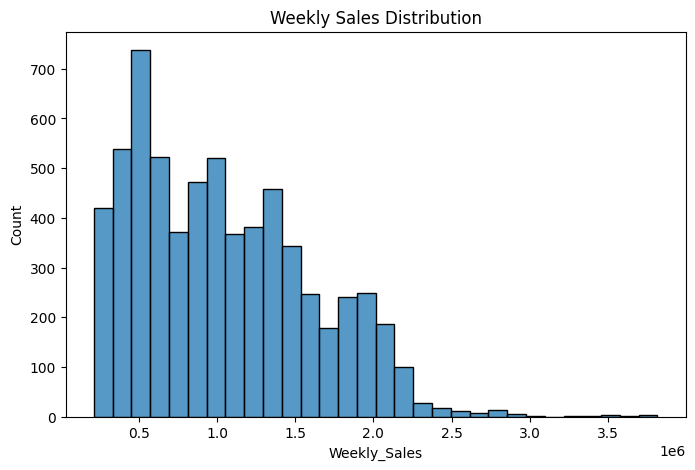

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Weekly_Sales'], bins=30)
plt.title("Weekly Sales Distribution")
plt.show()

###Outlier Detection

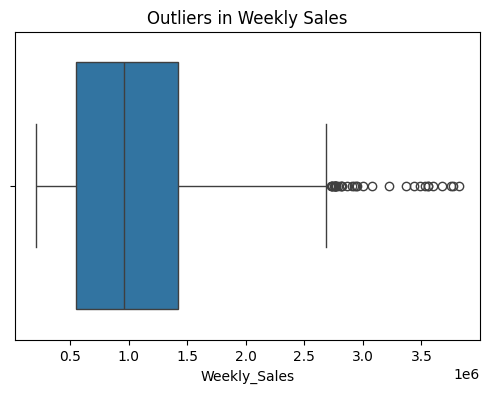

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Weekly_Sales'])
plt.title("Outliers in Weekly Sales")
plt.show()

### Remove Outlier
#### using IQR val Method

In [ ]:
Q1 = df['Weekly_Sales'].quantile(0.25)
Q3 = df['Weekly_Sales'].quantile(0.75)
IQR = Q3 - Q1

df = df[(df['Weekly_Sales'] > Q1 - 1.5*IQR) &
        (df['Weekly_Sales'] < Q3 + 1.5*IQR)]

### checking again for Outlier

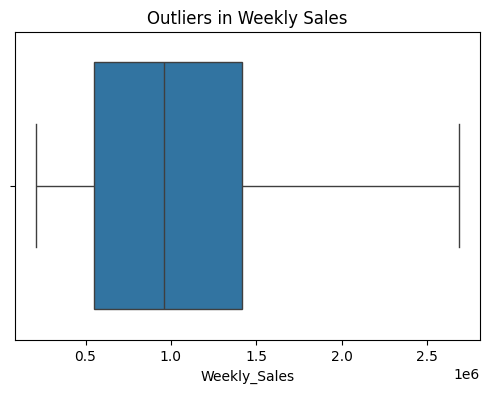

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Weekly_Sales'])
plt.title("Outliers in Weekly Sales")
plt.show()

###QUESTION-WISE SOLUTIONS
###(1) (a) Unemployment vs Weekly Sales

In [ ]:
df[['Weekly_Sales', 'Unemployment']].corr()

,Weekly_Sales,Unemployment
Weekly_Sales,1.000000,-0.104298
Unemployment,-0.104298,1.000000


####Plot

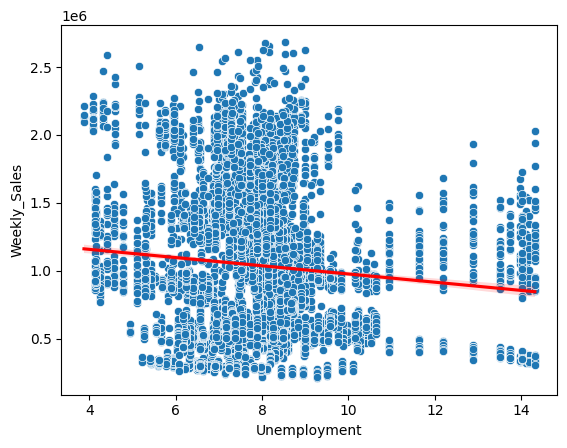

In [ ]:
sns.scatterplot(x='Unemployment', y='Weekly_Sales', data=df)
sns.regplot(x='Unemployment', y='Weekly_Sales', data=df, scatter=False, color='red')
plt.show()

####Store-wise Impact

In [ ]:
store_corr = df.groupby('Store').apply(
    lambda x: x['Weekly_Sales'].corr(x['Unemployment'])
).reset_index(name='Correlation')

store_corr.sort_values(by='Correlation')

/tmp/ipykernel_494/1337419251.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  store_corr = df.groupby('Store').apply(


,Store,Correlation
37,38,-0.785290
43,44,-0.780076
3,4,-0.639563
12,13,-0.400254
38,39,-0.384681
41,42,-0.356355
40,41,-0.350630
16,17,-0.263600
2,3,-0.230413
36,37,-0.221287


Insights:

(i) Negative correlation → higher unemployment reduces sales.

(ii) Stores with lowest correlation are most affected.

###(1) (b) Seasonal Trend

####Monthly Trend

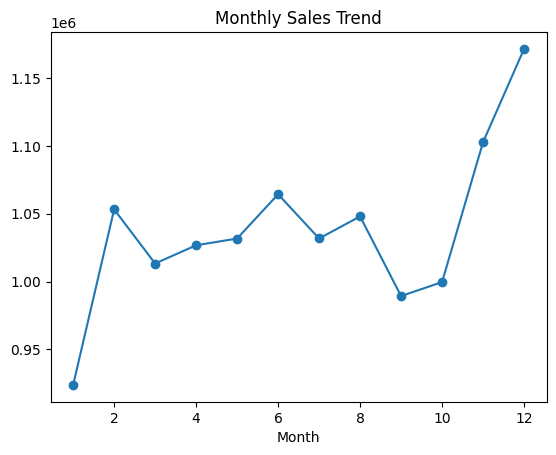

In [ ]:
monthly_sales = df.groupby('Month')['Weekly_Sales'].mean()

monthly_sales.plot(marker='o')
plt.title("Monthly Sales Trend")
plt.show()

####Holiday Impact

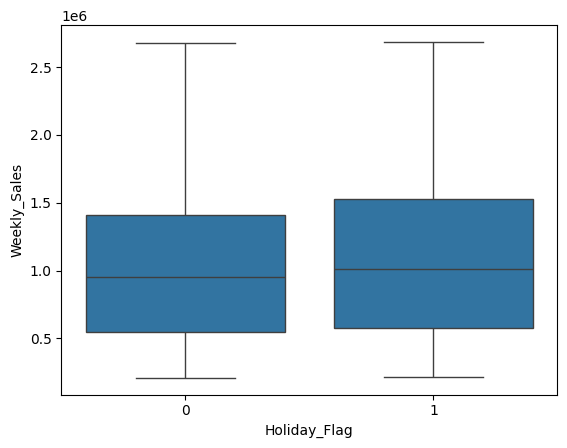

In [ ]:
sns.boxplot(x='Holiday_Flag', y='Weekly_Sales', data=df)
plt.show()

#####Insights:

(i) Sales spike during holidays.                                              
(ii) Peak: Nov–Dec (Christmas), Feb (Super Bowl).

###(1) (c) Temperature Effect

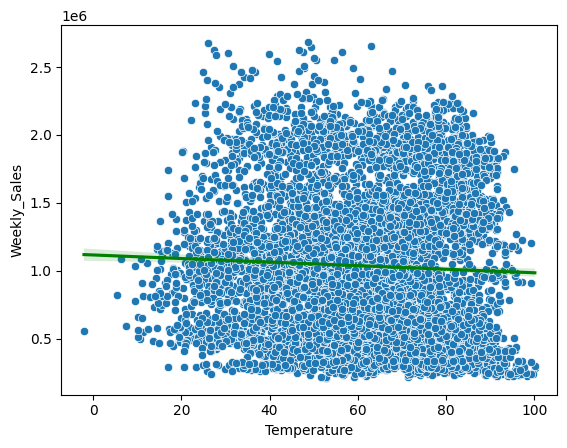

,Temperature,Weekly_Sales
Temperature,1.00000,-0.04434
Weekly_Sales,-0.04434,1.00000


In [ ]:
sns.scatterplot(x='Temperature', y='Weekly_Sales', data=df)
sns.regplot(x='Temperature', y='Weekly_Sales', data=df, scatter=False, color='green')
plt.show()

df[['Temperature','Weekly_Sales']].corr()

#####Insights:

(i) Weak relationship.                                                         
(ii) Moderate weather supports better sales.


###(1) (d) CPI Effect

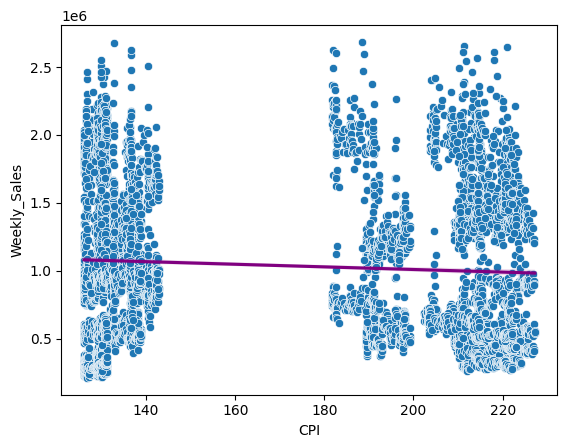

,CPI,Weekly_Sales
CPI,1.000000,-0.069617
Weekly_Sales,-0.069617,1.000000


In [ ]:
sns.scatterplot(x='CPI', y='Weekly_Sales', data=df)
sns.regplot(x='CPI', y='Weekly_Sales', data=df, scatter=False, color='purple')
plt.show()

df[['CPI','Weekly_Sales']].corr()

#####Insights:

(i) Moderate impact.                                                           
(ii) Higher CPI may reduce purchasing power.


###(1) (e) Top Performing Stores

In [ ]:
top_stores = df.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)
top_stores.head(10)

,Weekly_Sales
Store,
4,2.810352e+08
20,2.800237e+08
14,2.761276e+08
2,2.687221e+08
13,2.682025e+08
10,2.556789e+08
27,2.480387e+08
1,2.224028e+08
6,2.210286e+08


####Plot

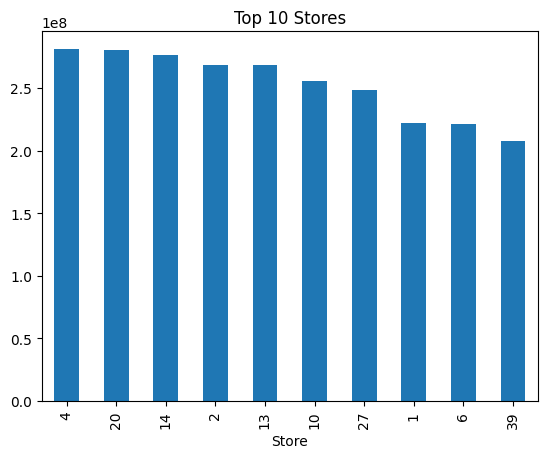

In [ ]:
top_stores.head(10).plot(kind='bar')
plt.title("Top 10 Stores")
plt.show()

###(1) (f) Worst Store & Difference

In [ ]:
best_store = top_stores.idxmax()
worst_store = top_stores.idxmin()

difference = top_stores.max() - top_stores.min()

print("Best Store:", best_store)
print("Worst Store:", worst_store)
print("Sales Difference:", difference)

Best Store: 4
Worst Store: 33
Sales Difference: 243875002.96


###(2) Forecasting (Next 12 Weeks)


####Example: Store 1

In [ ]:
store1 = df[df['Store'] == 1].sort_values('Date')

ts = store1.set_index('Date')['Weekly_Sales']

####Check Stationarity

In [ ]:
result = adfuller(ts)
print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -5.102186145192288
p-value: 1.3877788330759434e-05


####Auto ARIMA Model

In [ ]:
model = auto_arima(ts, seasonal=True, m=52, trace=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[52] intercept   : AIC=3786.582, Time=13.24 sec
 ARIMA(0,1,0)(0,0,0)[52] intercept   : AIC=3850.005, Time=0.05 sec
 ARIMA(1,1,0)(1,0,0)[52] intercept   : AIC=3795.624, Time=6.07 sec
 ARIMA(0,1,1)(0,0,1)[52] intercept   : AIC=3798.433, Time=3.54 sec
 ARIMA(0,1,0)(0,0,0)[52]             : AIC=3848.013, Time=0.03 sec
 ARIMA(2,1,2)(0,0,1)[52] intercept   : AIC=3795.311, Time=4.47 sec
 ARIMA(2,1,2)(1,0,0)[52] intercept   : AIC=3786.204, Time=3.74 sec
 ARIMA(2,1,2)(0,0,0)[52] intercept   : AIC=3819.024, Time=0.84 sec
 ARIMA(2,1,2)(2,0,0)[52] intercept   : AIC=3786.759, Time=60.46 sec
 ARIMA(2,1,2)(2,0,1)[52] intercept   : AIC=3788.572, Time=27.19 sec
 ARIMA(1,1,2)(1,0,0)[52] intercept   : AIC=3785.525, Time=5.18 sec
 ARIMA(1,1,2)(0,0,0)[52] intercept   : AIC=3819.410, Time=0.32 sec
 ARIMA(1,1,2)(2,0,0)[52] intercept   : AIC=inf, Time=39.39 sec
 ARIMA(1,1,2)(1,0,1)[52] intercept   : AIC=3786.145, Time=5.16 sec
 ARIMA(1,1,2)(0,0,1)

####Forecast 12 Weeks

In [ ]:
forecast = model.predict(n_periods=12)

future_dates = pd.date_range(start=ts.index[-1], periods=13, freq='W')[1:]

forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast': forecast
})

print(forecast_df)

                 Date      Forecast
2012-11-02 2012-11-04  1.638781e+06
2012-11-09 2012-11-11  1.596926e+06
2012-11-16 2012-11-18  1.573151e+06
2012-11-23 2012-11-25  1.818433e+06
2012-11-30 2012-12-02  1.597295e+06
2012-12-07 2012-12-09  1.703985e+06
2012-12-14 2012-12-16  1.744323e+06
2012-12-21 2012-12-23  1.936403e+06
2012-12-28 2012-12-30  1.554968e+06
2013-01-04 2013-01-06  1.581093e+06
2013-01-11 2013-01-13  1.536289e+06
2013-01-18 2013-01-20  1.504101e+06


####Plot Forecast

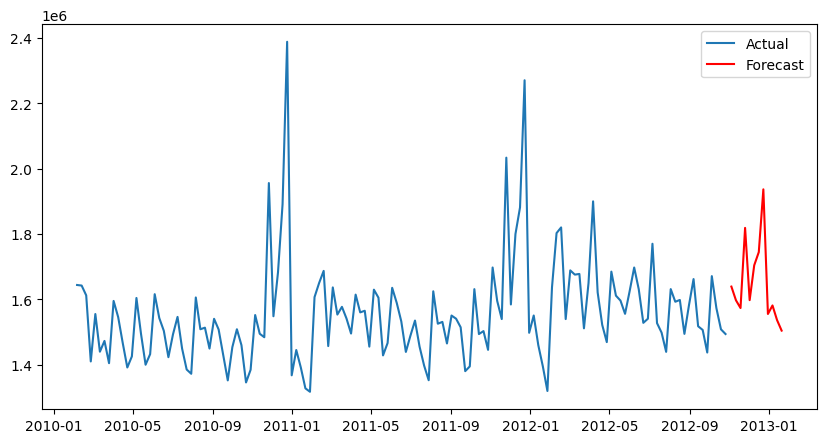

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(ts, label='Actual')
plt.plot(forecast_df['Date'], forecast_df['Forecast'], label='Forecast', color='red')
plt.legend()
plt.show()

####Forecast for All Stores

In [ ]:
forecast_dict = {}

for store in df['Store'].unique():
    print(f"Processing Store {store}")

    temp = df[df['Store'] == store].sort_values('Date')
    ts_temp = temp.set_index('Date')['Weekly_Sales']

    model = auto_arima(
        ts_temp,
        seasonal=True,
        m=52,
        stepwise=True,
        suppress_warnings=True,
        error_action='ignore',
        max_p=3,
        max_q=3,
        max_P=1,
        max_Q=1
    )

    forecast = model.predict(n_periods=12)

    future_dates = pd.date_range(
        start=ts_temp.index[-1] + pd.Timedelta(weeks=1),
        periods=12,
        freq='W'
    )

    forecast_dict[store] = pd.DataFrame({
        'Date': future_dates,
        'Forecast': forecast
    })

Processing Store 1
Processing Store 2


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


Processing Store 3
Processing Store 4


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


Processing Store 5
Processing Store 6


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


... (9 outputs left out)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


Processing Store 24
Processing Store 25
Processing Store 26
Processing Store 27


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


Processing Store 28
Processing Store 29
Processing Store 30
Processing Store 31
Processing Store 32
Processing Store 33
Processing Store 34
Processing Store 35
Processing Store 36
Processing Store 37
Processing Store 38
Processing Store 39
Processing Store 40
Processing Store 41
Processing Store 42
Processing Store 43
Processing Store 44
Processing Store 45


In [ ]:
forecast_df = forecast_dict[1].reset_index()

print(forecast_df.head())

       index       Date      Forecast
0 2012-11-02 2012-11-04  1.638781e+06
1 2012-11-09 2012-11-11  1.596926e+06
2 2012-11-16 2012-11-18  1.573151e+06
3 2012-11-23 2012-11-25  1.818433e+06
4 2012-11-30 2012-12-02  1.597295e+06


###plot forcast for first five store

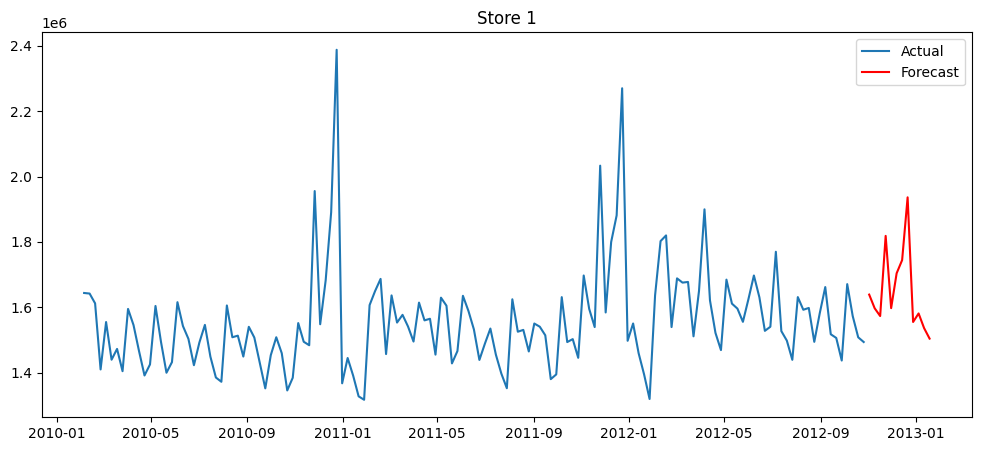

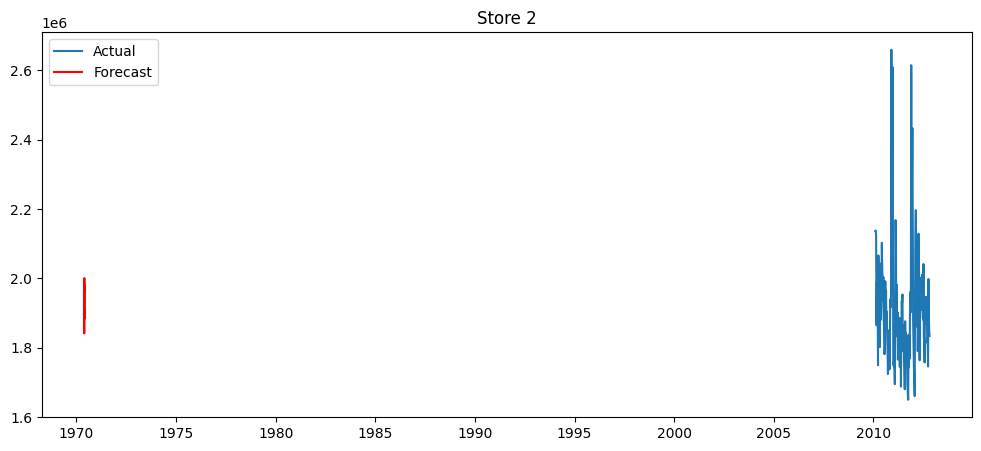

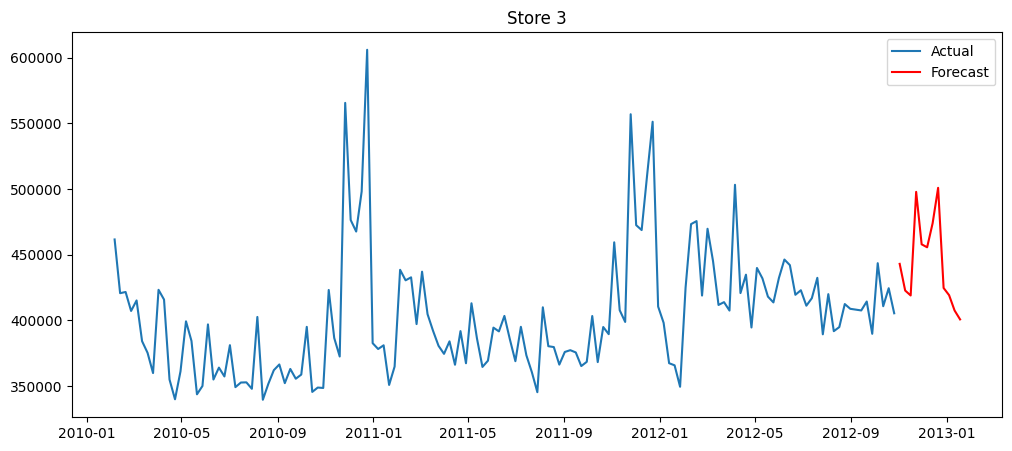

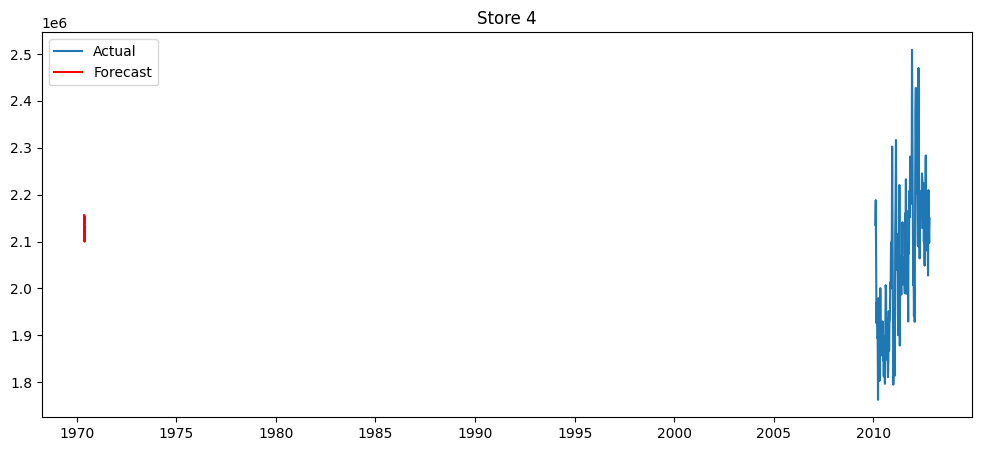

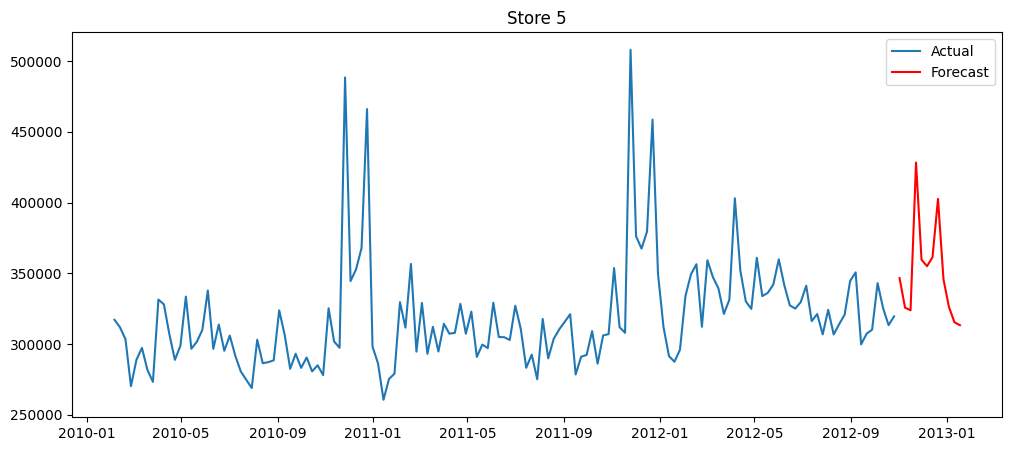

In [ ]:
for store in list(forecast_dict.keys())[:5]:

    temp = df[df['Store'] == store].sort_values('Date')
    ts = temp.set_index('Date')['Weekly_Sales']

    forecast_df = forecast_dict[store]

    plt.figure(figsize=(12,5))
    plt.plot(ts.index, ts.values, label='Actual')
    plt.plot(forecast_df.index, forecast_df['Forecast'],
             color='red', label='Forecast')
    plt.title(f'Store {store}')
    plt.legend()
    plt.show()

#####Final Insights:

(i) Unemployment negatively impacts sales.                
(ii) Sales show strong seasonal trends (holidays boost sales).                                     
(iii) Temperature has weak influence.                      
(iv) CPI moderately affects sales.                         
(v) Some stores consistently outperform others.            
(vi) Large gap exists between best & worst stores.           
(vii) ARIMA provides reliable short-term forecasts.